In [1]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
from scipy.linalg import expm, logm


In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

In [3]:
train_fnc = pd.read_csv('train/train_FNC.csv')
train_labels = pd.read_csv('train/train_labels.csv')
test_path = 'test/test_FNC.csv'
test_fnc = pd.read_csv(test_path) if os.path.exists(test_path) else None

print(f"Train FNC shape: {train_fnc.shape}")
print(f"Test FNC shape: {test_fnc.shape if test_fnc is not None else 'not available'}")

train_ids = train_fnc['Id'].values
X_train_raw = train_fnc.drop(columns=['Id']).values.astype(np.float32)
if test_fnc is not None:
    test_ids = test_fnc['Id'].values
    X_test_raw = test_fnc.drop(columns=['Id']).values.astype(np.float32)
else:
    test_ids = np.array([], dtype=train_ids.dtype)
    X_test_raw = np.empty((0, X_train_raw.shape[1]), dtype=np.float32)
y_train = train_labels['Class'].values.astype(np.int64)


Train FNC shape: (86, 379)
Test FNC shape: not available


In [4]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
input_dim = X_train.shape[1]
X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)

print(f"Input dim: {input_dim}, train n={len(X_train)}")

Input dim: 378, train n=86


In [5]:
class FlexAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=2, hidden_dims=(128, 64, 16),
                 activation='relu', dropout=0.0):
        super().__init__()
        act_cls = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'leaky': nn.LeakyReLU}[activation]

        enc_layers = []
        prev = input_dim
        for h in hidden_dims:
            enc_layers.append(nn.Linear(prev, h))
            enc_layers.append(act_cls())
            if dropout > 0:
                enc_layers.append(nn.Dropout(dropout))
            prev = h
        enc_layers.append(nn.Linear(prev, latent_dim))
        self.encoder = nn.Sequential(*enc_layers)

        dec_layers = []
        prev = latent_dim
        for h in reversed(hidden_dims):
            dec_layers.append(nn.Linear(prev, h))
            dec_layers.append(act_cls())
            prev = h
        dec_layers.append(nn.Linear(prev, input_dim))
        self.decoder = nn.Sequential(*dec_layers)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

    def encode(self, x):
        return self.encoder(x)

In [6]:
def train_autoencoder(X, config, verbose=False):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = FlexAutoencoder(
        input_dim=X.shape[1],
        latent_dim=config['latent_dim'],
        hidden_dims=config['hidden_dims'],
        activation=config['activation'],
        dropout=config['dropout'],
    ).to(device)

    criterion = nn.MSELoss()
    opt_cls = optim.AdamW if config['optimizer'] == 'adamw' else optim.Adam
    optimizer = opt_cls(model.parameters(), lr=config['lr'],
                        weight_decay=config.get('weight_decay', 0.0))

    loader = DataLoader(TensorDataset(torch.from_numpy(X)),
                        batch_size=config['batch_size'], shuffle=True)
    losses = []
    model.train()
    for epoch in range(config['epochs']):
        total = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            recon, _ = model(batch)
            loss = criterion(recon, batch)
            loss.backward()
            optimizer.step()
            total += loss.item() * batch.size(0)
        losses.append(total / len(X))
        if verbose and (epoch + 1) % 20 == 0:
            print(f"    epoch {epoch+1:3d}  MSE={losses[-1]:.6f}")
    return model, losses


def encode_in_batches(model, X_raw, scaler, batch_size=8192):
    model.eval()
    device = next(model.parameters()).device
    n = X_raw.shape[0]
    with torch.no_grad():
        _ = model.encode(torch.zeros(1, X_raw.shape[1]).to(device))
    latent_dim = _.shape[1]
    out = np.zeros((n, latent_dim), dtype=np.float32)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        chunk = scaler.transform(X_raw[start:end]).astype(np.float32)
        chunk = np.nan_to_num(chunk, nan=0.0)
        with torch.no_grad():
            z = model.encode(torch.from_numpy(chunk).to(device)).cpu().numpy()
        out[start:end] = z
    return out

In [7]:
AE_CONFIGS = {
    'AE_baseline_4L': dict(
        hidden_dims=(input_dim // 2, input_dim // 8, input_dim // 32),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_shallow_2L': dict(
        hidden_dims=(input_dim // 4, input_dim // 16),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_deep_5L': dict(
        hidden_dims=(256, 128, 64, 32, 16),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_wide': dict(
        hidden_dims=(512, 256, 64),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_narrow': dict(
        hidden_dims=(64, 32, 8),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_dropout': dict(
        hidden_dims=(128, 64, 16),
        latent_dim=2, activation='relu', dropout=0.3,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_tanh': dict(
        hidden_dims=(128, 64, 16),
        latent_dim=2, activation='tanh', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_300ep': dict(
        hidden_dims=(128, 64, 16),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=300, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
    'AE_lr1e-4': dict(
        hidden_dims=(128, 64, 16),
        latent_dim=2, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-4, optimizer='adamw',
    ),
    'AE_latent4': dict(
        hidden_dims=(128, 64, 16),
        latent_dim=4, activation='relu', dropout=0.0,
        epochs=100, batch_size=32, lr=1e-3, optimizer='adamw',
    ),
}

In [8]:
print("\n" + "="*70)
print("Training autoencoder variants")
print("="*70)

ae_models = {}
ae_losses = {}
Z_train_dict = {}
Z_test_dict = {}

for name, cfg in AE_CONFIGS.items():
    print(f"\n[{name}]  layers={len(cfg['hidden_dims'])}  "
          f"latent={cfg['latent_dim']}  act={cfg['activation']}  "
          f"drop={cfg['dropout']}  ep={cfg['epochs']}  lr={cfg['lr']}")
    model, losses = train_autoencoder(X_train, cfg, verbose=False)
    Z_tr = encode_in_batches(model, X_train_raw, scaler, batch_size=len(X_train_raw))
    Z_te = encode_in_batches(model, X_test_raw, scaler, batch_size=8192)
    ae_models[name] = model
    ae_losses[name] = losses
    Z_train_dict[name] = Z_tr
    Z_test_dict[name] = Z_te
    print(f"  final MSE={losses[-1]:.6f}  Z_train={Z_tr.shape}  Z_test={Z_te.shape}")


Training autoencoder variants

[AE_baseline_4L]  layers=3  latent=2  act=relu  drop=0.0  ep=100  lr=0.001


  final MSE=0.558085  Z_train=(86, 2)  Z_test=(0, 2)

[AE_shallow_2L]  layers=2  latent=2  act=relu  drop=0.0  ep=100  lr=0.001


  final MSE=0.589091  Z_train=(86, 2)  Z_test=(0, 2)

[AE_deep_5L]  layers=5  latent=2  act=relu  drop=0.0  ep=100  lr=0.001


  final MSE=0.606585  Z_train=(86, 2)  Z_test=(0, 2)

[AE_wide]  layers=3  latent=2  act=relu  drop=0.0  ep=100  lr=0.001


  final MSE=0.487129  Z_train=(86, 2)  Z_test=(0, 2)

[AE_narrow]  layers=3  latent=2  act=relu  drop=0.0  ep=100  lr=0.001


...

  final MSE=0.732092  Z_train=(86, 2)  Z_test=(0, 2)

[AE_tanh]  layers=3  latent=2  act=tanh  drop=0.0  ep=100  lr=0.001


  final MSE=0.739437  Z_train=(86, 2)  Z_test=(0, 2)

[AE_300ep]  layers=3  latent=2  act=relu  drop=0.0  ep=300  lr=0.001


  final MSE=0.346677  Z_train=(86, 2)  Z_test=(0, 2)

[AE_lr1e-4]  layers=3  latent=2  act=relu  drop=0.0  ep=100  lr=0.0001


  final MSE=0.875410  Z_train=(86, 2)  Z_test=(0, 2)

[AE_latent4]  layers=3  latent=4  act=relu  drop=0.0  ep=100  lr=0.001


  final MSE=0.404248  Z_train=(86, 4)  Z_test=(0, 4)


In [9]:
class MIAF(nn.Module):
    def __init__(self, group_dims, sub_encoder_dims, feature_dim, decoder_dims,
                 input_dim, activation='relu'):
        super().__init__()
        act_cls = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'leaky': nn.LeakyReLU}[activation]

        self.sub_encoders = nn.ModuleList()
        for d_in, d_h in zip(group_dims, sub_encoder_dims):
            self.sub_encoders.append(nn.Sequential(
                nn.Linear(d_in, d_h),
                act_cls(),
                nn.Linear(d_h, d_h),
                act_cls(),
            ))

        z_dim = sum(sub_encoder_dims)
        self.feature_selector = nn.Linear(z_dim, feature_dim)

        dec_layers = []
        prev = feature_dim
        for h in decoder_dims:
            dec_layers.append(nn.Linear(prev, h))
            dec_layers.append(act_cls())
            prev = h
        dec_layers.append(nn.Linear(prev, input_dim))
        self.decoder = nn.Sequential(*dec_layers)

    def forward(self, xs):
        es = [enc(x) for enc, x in zip(self.sub_encoders, xs)]
        z = torch.cat(es, dim=1)
        h = torch.relu(self.feature_selector(z))
        x_hat = self.decoder(h)
        return x_hat, z, h

    def encode_z(self, xs):
        with torch.no_grad():
            es = [enc(x) for enc, x in zip(self.sub_encoders, xs)]
            return torch.cat(es, dim=1)

In [10]:
def group_features_sym_kl(X, n_bins=20, gamma=0.5):
    n, d = X.shape
    hists = np.zeros((d, n_bins), dtype=np.float64)
    eps = 1e-12
    for t in range(d):
        col = X[:, t]
        vmin, vmax = col.min(), col.max()
        if vmax == vmin:
            hists[t, 0] = 1.0
            continue
        width = (vmax - vmin) / n_bins
        edges = vmin + width * np.arange(n_bins + 1)
        counts, _ = np.histogram(col, bins=edges)
        counts = counts.astype(np.float64) + eps
        hists[t] = counts / counts.sum()

    D = np.zeros((d, d), dtype=np.float64)
    for i in range(d):
        for j in range(i + 1, d):
            p, q = hists[i], hists[j]
            kl_pq = np.sum(p * np.log(p / q))
            kl_qp = np.sum(q * np.log(q / p))
            D[i, j] = D[j, i] = 0.5 * (kl_pq + kl_qp)

    condensed = squareform(D, checks=False)
    Z_linkage = linkage(condensed, method='average')

    labels = fcluster(Z_linkage, t=gamma, criterion='distance')
    groups = {}
    for feat_idx, lab in enumerate(labels):
        groups.setdefault(int(lab), []).append(feat_idx)
    group_list = [np.array(v, dtype=np.int64) for v in groups.values()]
    group_list.sort(key=lambda a: a[0])
    return group_list

In [11]:
def train_miaf(X, group_list, feature_dim=50, feature_hidden=64,
               sub_encoder_dim=16, decoder_dims=(128, 64, 32),
               l2_lambda=1.0, epochs=100, batch_size=32, lr=1e-3,
               activation='relu'):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    group_dims = [len(g) for g in group_list]
    sub_encoder_dims = [max(sub_encoder_dim, 4)] * len(group_list)

    model = MIAF(
        group_dims=group_dims,
        sub_encoder_dims=sub_encoder_dims,
        feature_dim=feature_dim,
        decoder_dims=decoder_dims,
        input_dim=X.shape[1],
        activation=activation,
    ).to(device)

    xs_full = [torch.from_numpy(X[:, g].astype(np.float32)).to(device)
               for g in group_list]
    n = X.shape[0]

    criterion = nn.MSELoss(reduction='sum')
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    losses = []
    for epoch in range(epochs):
        perm = torch.randperm(n, device=device)
        total = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            xs_batch = [x[idx] for x in xs_full]
            optimizer.zero_grad()
            x_hat, z, h = model(xs_batch)
            target = torch.cat([x[idx] for x in xs_full], dim=1)
            rec = criterion(x_hat, target) / len(idx)
            l21 = torch.norm(model.feature_selector.weight, p=2, dim=1).sum()
            loss = rec + l2_lambda * l21
            loss.backward()
            optimizer.step()
            total += rec.item() * len(idx)
        losses.append(total / n)
    return model, losses


def miaf_encode_in_batches(model, X_raw, scaler, group_list, batch_size=8192):
    model.eval()
    device = next(model.parameters()).device
    n = X_raw.shape[0]
    z_dim = sum(m[-2].out_features for m in model.sub_encoders)
    out = np.zeros((n, z_dim), dtype=np.float32)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        chunk = scaler.transform(X_raw[start:end]).astype(np.float32)
        chunk = np.nan_to_num(chunk, nan=0.0)
        xs = [torch.from_numpy(chunk[:, g]).to(device) for g in group_list]
        with torch.no_grad():
            z = model.encode_z(xs).cpu().numpy()
        out[start:end] = z
    return out


def miaf_feature_importance(model):
    W = model.feature_selector.weight.detach().cpu().numpy()
    return np.sqrt((W ** 2).sum(axis=1))


def miaf_select_top(z, importance, ratio):
    k = max(1, int(len(importance) * ratio))
    order = np.argsort(-importance)[:k]
    return z[:, order], order

In [12]:
print("\n" + "="*70)
print("Training MIAF (multiple-input AE + feature selection)")
print("="*70)

group_list = group_features_sym_kl(X_train, n_bins=20, gamma=0.5)
print(f"Algorithm 1 produced {len(group_list)} feature groups")
print(f"Group sizes: {[len(g) for g in group_list]}")

MIAF_CONFIGS = {
    'MIAF_z50': dict(feature_dim=50, l2_lambda=1.0, epochs=100),
    'MIAF_z20': dict(feature_dim=20, l2_lambda=1.0, epochs=100),
    'MIAF_z10': dict(feature_dim=10, l2_lambda=1.0, epochs=100),
    'MIAF_l2_5': dict(feature_dim=50, l2_lambda=5.0, epochs=100),
}

for name, cfg in MIAF_CONFIGS.items():
    print(f"\n[{name}]  feature_dim={cfg['feature_dim']}  "
          f"lambda={cfg['l2_lambda']}  groups={len(group_list)}")
    model, losses = train_miaf(
        X_train, group_list,
        feature_dim=cfg['feature_dim'],
        l2_lambda=cfg['l2_lambda'],
        epochs=cfg['epochs'],
        batch_size=32, lr=1e-3,
    )
    Z_tr = miaf_encode_in_batches(model, X_train_raw, scaler, group_list,
                                  batch_size=len(X_train_raw))
    Z_te = miaf_encode_in_batches(model, X_test_raw, scaler, group_list,
                                  batch_size=8192)
    ae_models[name] = model
    ae_losses[name] = losses
    Z_train_dict[name] = Z_tr
    Z_test_dict[name] = Z_te
    imp = miaf_feature_importance(model)
    print(f"  final rec MSE={losses[-1]:.6f}  Z_train={Z_tr.shape}  "
          f"Z_test={Z_te.shape}  imp[min/med/max]="
          f"{imp.min():.4f}/{np.median(imp):.4f}/{imp.max():.4f}")


Training MIAF (multiple-input AE + feature selection)


Algorithm 1 produced 66 feature groups
Group sizes: [7, 5, 1, 4, 1, 74, 4, 31, 15, 5, 9, 4, 5, 35, 13, 1, 4, 3, 6, 32, 21, 4, 9, 1, 1, 4, 3, 4, 5, 3, 1, 1, 2, 2, 5, 3, 3, 1, 2, 2, 2, 4, 4, 1, 2, 1, 1, 1, 1, 1, 2, 3, 1, 5, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1]

[MIAF_z50]  feature_dim=50  lambda=1.0  groups=66


  final rec MSE=245.349326  Z_train=(86, 1056)  Z_test=(0, 1056)  imp[min/med/max]=0.0009/0.0629/0.3403

[MIAF_z20]  feature_dim=20  lambda=1.0  groups=66


  final rec MSE=248.062986  Z_train=(86, 1056)  Z_test=(0, 1056)  imp[min/med/max]=0.0010/0.2065/0.3686

[MIAF_z10]  feature_dim=10  lambda=1.0  groups=66


  final rec MSE=239.118052  Z_train=(86, 1056)  Z_test=(0, 1056)  imp[min/med/max]=0.0008/0.3591/0.4638

[MIAF_l2_5]  feature_dim=50  lambda=5.0  groups=66


  final rec MSE=317.246449  Z_train=(86, 1056)  Z_test=(0, 1056)  imp[min/med/max]=0.0008/0.0039/0.0992


In [13]:
classifiers = {
    'KNN (k=5)':     KNeighborsClassifier(n_neighbors=5),
    'Logistic Reg.': LogisticRegression(max_iter=1000, random_state=42),
    'SVM (RBF)':     SVC(kernel='rbf', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

train_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.25,
    random_state=42, stratify=y_train
)
y_tr, y_val = y_train[train_idx], y_train[val_idx]
print(f"\nHeld-out split: train={len(train_idx)}, val={len(val_idx)}")


Held-out split: train=64, val=22


In [14]:
results = []
print("\n" + "="*70)
print("Validation accuracy: all reducers (AE variants + MIAF) x classifier")
print("="*70)

for red_name, Z_tr_full in Z_train_dict.items():
    for clf_name, clf in classifiers.items():
        clf.fit(Z_tr_full[train_idx], y_tr)
        acc = accuracy_score(y_val, clf.predict(Z_tr_full[val_idx]))
        results.append((red_name, clf_name, acc))
        print(f"  {red_name:18s} | {clf_name:14s} | acc={acc:.4f}")

results_df = pd.DataFrame(results, columns=['Reducer', 'Classifier', 'Val_Acc'])
pivot = results_df.pivot(index='Reducer', columns='Classifier', values='Val_Acc')
print("\nPivot (validation accuracy):")
print(pivot.round(4).to_string())


Validation accuracy: all reducers (AE variants + MIAF) x classifier
  AE_baseline_4L     | KNN (k=5)      | acc=0.7273
  AE_baseline_4L     | Logistic Reg.  | acc=0.6364
  AE_baseline_4L     | SVM (RBF)      | acc=0.5909
  AE_baseline_4L     | Random Forest  | acc=0.6364
  AE_shallow_2L      | KNN (k=5)      | acc=0.5909
  AE_shallow_2L      | Logistic Reg.  | acc=0.5000
  AE_shallow_2L      | SVM (RBF)      | acc=0.5455
  AE_shallow_2L      | Random Forest  | acc=0.7273
  AE_deep_5L         | KNN (k=5)      | acc=0.5455
  AE_deep_5L         | Logistic Reg.  | acc=0.6818
  AE_deep_5L         | SVM (RBF)      | acc=0.5000


  AE_deep_5L         | Random Forest  | acc=0.5909
  AE_wide            | KNN (k=5)      | acc=0.6364
  AE_wide            | Logistic Reg.  | acc=0.4545
  AE_wide            | SVM (RBF)      | acc=0.5455
  AE_wide            | Random Forest  | acc=0.5909
  AE_narrow          | KNN (k=5)      | acc=0.5909
  AE_narrow          | Logistic Reg.  | acc=0.7727
  AE_narrow          | SVM (RBF)      | acc=0.6818


  AE_narrow          | Random Forest  | acc=0.6364
  AE_dropout         | KNN (k=5)      | acc=0.6364
  AE_dropout         | Logistic Reg.  | acc=0.5909
  AE_dropout         | SVM (RBF)      | acc=0.6818
  AE_dropout         | Random Forest  | acc=0.5455
  AE_tanh            | KNN (k=5)      | acc=0.7273
  AE_tanh            | Logistic Reg.  | acc=0.6818
  AE_tanh            | SVM (RBF)      | acc=0.6364


  AE_tanh            | Random Forest  | acc=0.6818
  AE_300ep           | KNN (k=5)      | acc=0.5909
  AE_300ep           | Logistic Reg.  | acc=0.5455
  AE_300ep           | SVM (RBF)      | acc=0.5000
  AE_300ep           | Random Forest  | acc=0.5000
  AE_lr1e-4          | KNN (k=5)      | acc=0.6818
  AE_lr1e-4          | Logistic Reg.  | acc=0.5455
  AE_lr1e-4          | SVM (RBF)      | acc=0.5909
  AE_lr1e-4          | Random Forest  | acc=0.7727


  AE_latent4         | KNN (k=5)      | acc=0.6364
  AE_latent4         | Logistic Reg.  | acc=0.5909
  AE_latent4         | SVM (RBF)      | acc=0.5909
  AE_latent4         | Random Forest  | acc=0.6818
  MIAF_z50           | KNN (k=5)      | acc=0.6818
  MIAF_z50           | Logistic Reg.  | acc=0.7727
  MIAF_z50           | SVM (RBF)      | acc=0.7273


  MIAF_z50           | Random Forest  | acc=0.7273
  MIAF_z20           | KNN (k=5)      | acc=0.5909
  MIAF_z20           | Logistic Reg.  | acc=0.7273
  MIAF_z20           | SVM (RBF)      | acc=0.6364
  MIAF_z20           | Random Forest  | acc=0.6364
  MIAF_z10           | KNN (k=5)      | acc=0.5909
  MIAF_z10           | Logistic Reg.  | acc=0.6818
  MIAF_z10           | SVM (RBF)      | acc=0.7273


  MIAF_z10           | Random Forest  | acc=0.6364
  MIAF_l2_5          | KNN (k=5)      | acc=0.6364
  MIAF_l2_5          | Logistic Reg.  | acc=0.6818
  MIAF_l2_5          | SVM (RBF)      | acc=0.6818
  MIAF_l2_5          | Random Forest  | acc=0.5909

Pivot (validation accuracy):
Classifier      KNN (k=5)  Logistic Reg.  Random Forest  SVM (RBF)
Reducer                                                           
AE_300ep           0.5909         0.5455         0.5000     0.5000
AE_baseline_4L     0.7273         0.6364         0.6364     0.5909
AE_deep_5L         0.5455         0.6818         0.5909     0.5000
AE_dropout         0.6364         0.5909         0.5455     0.6818
AE_latent4         0.6364         0.5909         0.6818     0.5909
AE_lr1e-4          0.6818         0.5455         0.7727     0.5909
AE_narrow          0.5909         0.7727         0.6364     0.6818
AE_shallow_2L      0.5909         0.5000         0.7273     0.5455
AE_tanh            0.7273         0.6818     

In [15]:
miaf_name = 'MIAF_z50'
z_tr_full = Z_train_dict[miaf_name]
z_te_full = Z_test_dict[miaf_name]
imp = miaf_feature_importance(ae_models[miaf_name])

print(f"\nMIAF feature-selection ablation on {miaf_name}")
print(f"z dim = {z_tr_full.shape[1]}, importance range "
      f"[{imp.min():.4f}, {imp.max():.4f}]")

knn = KNeighborsClassifier(n_neighbors=5)
ratios = [1.0, 0.8, 0.6, 0.4, 0.2]
ablation = []
for r in ratios:
    z_tr_sel, order = miaf_select_top(z_tr_full, imp, r)
    knn.fit(z_tr_sel[train_idx], y_tr)
    acc = accuracy_score(y_val, knn.predict(z_tr_sel[val_idx]))
    ablation.append((r, z_tr_sel.shape[1], acc))
    print(f"  ratio={r:.1f}  kept={z_tr_sel.shape[1]:2d}  "
          f"KNN5 val acc={acc:.4f}")

ablation_df = pd.DataFrame(ablation, columns=['ratio', 'n_kept', 'val_acc'])
ablation_df.to_csv('miaf_feature_selection_ablation.csv', index=False)
print("Saved miaf_feature_selection_ablation.csv")


MIAF feature-selection ablation on MIAF_z50
z dim = 1056, importance range [0.0009, 0.3403]
  ratio=1.0  kept=50  KNN5 val acc=0.7273
  ratio=0.8  kept=40  KNN5 val acc=0.5909
  ratio=0.6  kept=30  KNN5 val acc=0.7273
  ratio=0.4  kept=20  KNN5 val acc=0.5000
  ratio=0.2  kept=10  KNN5 val acc=0.4545
Saved miaf_feature_selection_ablation.csv


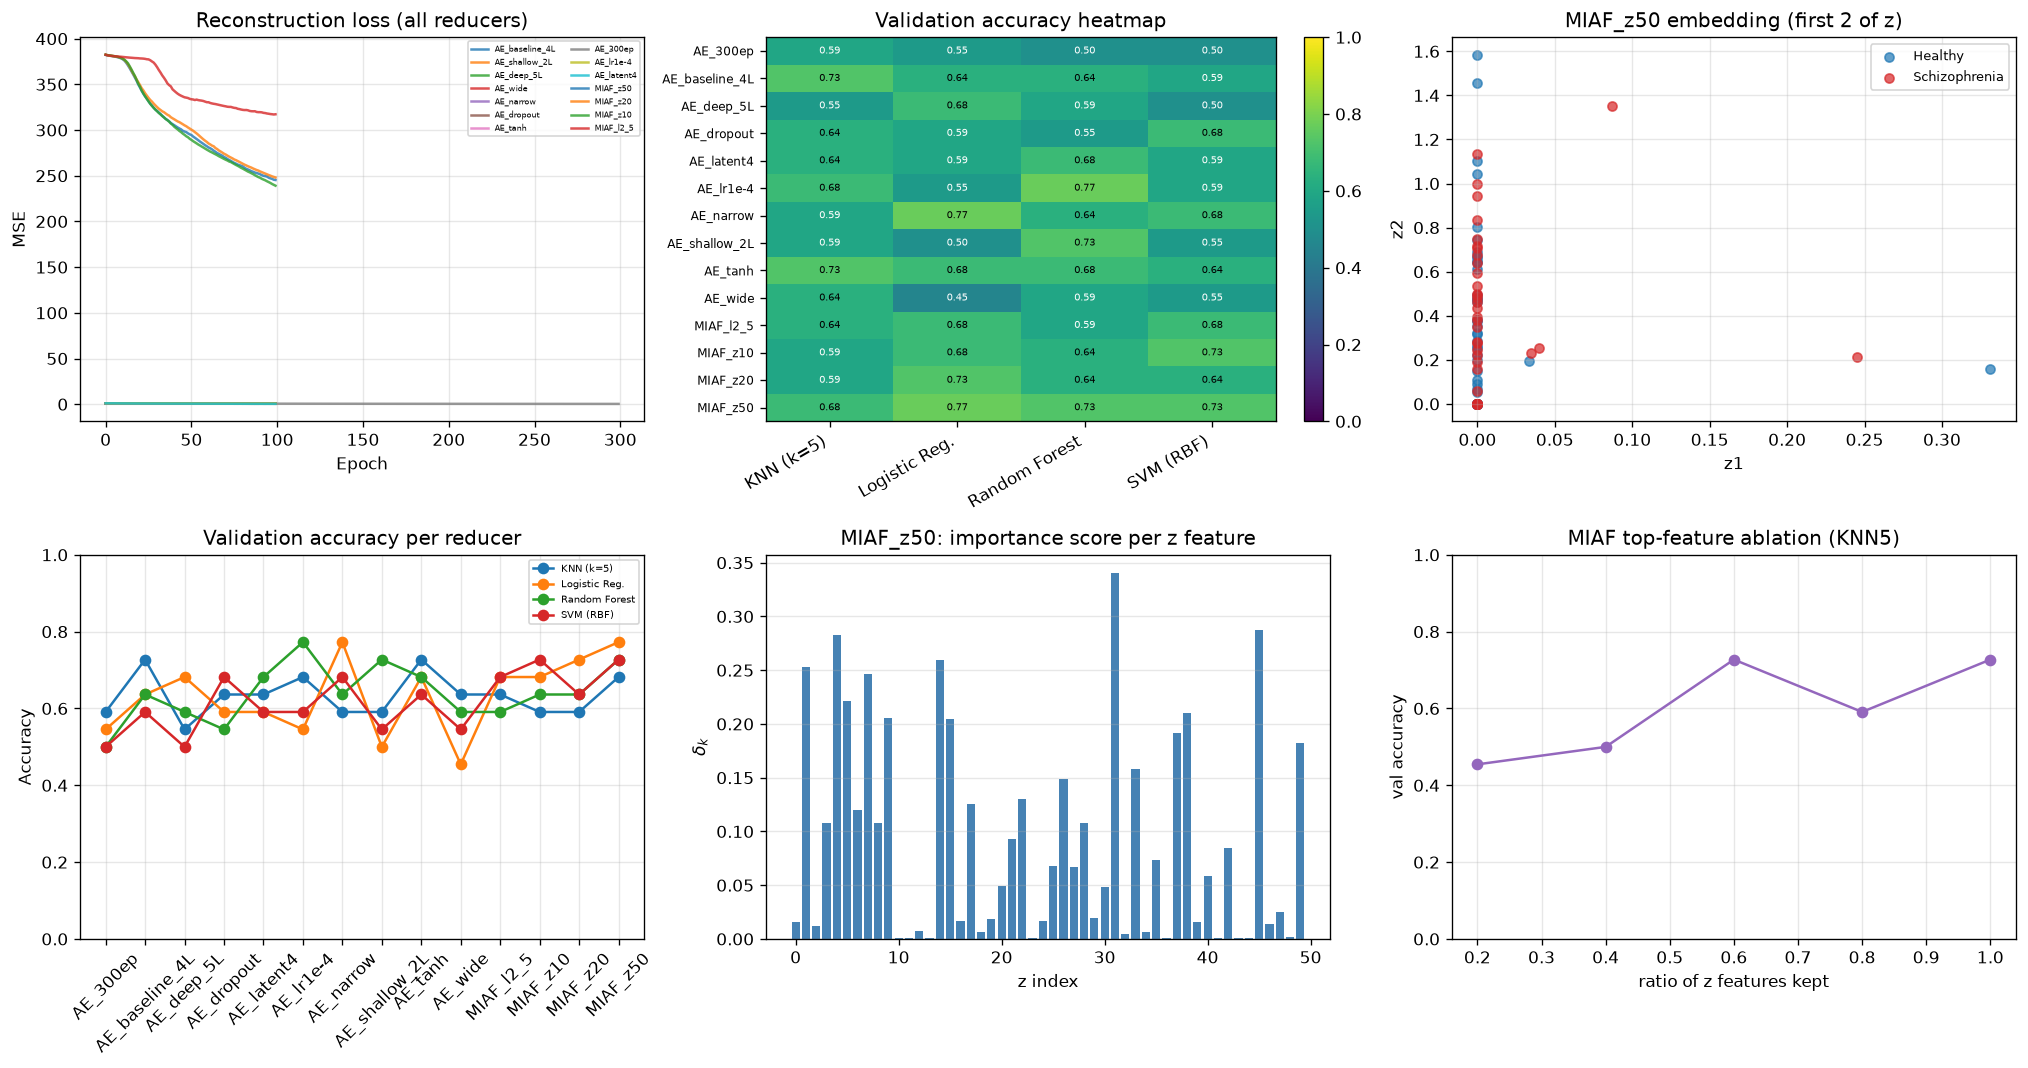


Saved figure to autoencoder_and_miaf_results.png


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

ax = axes[0, 0]
for name, losses in ae_losses.items():
    ax.plot(losses, label=name, alpha=0.8)
ax.set_title('Reconstruction loss (all reducers)')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE')
ax.legend(fontsize=5, ncol=2); ax.grid(alpha=0.3)

ax = axes[0, 1]
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30, ha='right')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=7)
ax.set_title('Validation accuracy heatmap')
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f'{pivot.values[i,j]:.2f}',
                ha='center', va='center',
                color='white' if pivot.values[i,j] < 0.6 else 'black',
                fontsize=6)
plt.colorbar(im, ax=ax, fraction=0.046)

ax = axes[0, 2]
z = Z_train_dict[miaf_name]
for c, label, color in [(0, 'Healthy', 'tab:blue'),
                        (1, 'Schizophrenia', 'tab:red')]:
    m = y_train == c
    ax.scatter(z[m, 0], z[m, 1], s=30, alpha=0.7, color=color, label=label)
ax.set_title(f'{miaf_name} embedding (first 2 of z)')
ax.set_xlabel('z1'); ax.set_ylabel('z2')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1, 0]
for clf_name in pivot.columns:
    ax.plot(pivot.index, pivot[clf_name], marker='o', label=clf_name)
ax.set_title('Validation accuracy per reducer')
ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=6); ax.grid(alpha=0.3)

ax = axes[1, 1]
ax.bar(np.arange(len(imp)), imp, color='steelblue')
ax.set_title(f'{miaf_name}: importance score per z feature')
ax.set_xlabel('z index'); ax.set_ylabel(r'$\delta_k$')
ax.grid(alpha=0.3, axis='y')

ax = axes[1, 2]
ax.plot([r for r, _, _ in ablation],
        [a for _, _, a in ablation], marker='o', color='tab:purple')
ax.set_title('MIAF top-feature ablation (KNN5)')
ax.set_xlabel('ratio of z features kept')
ax.set_ylabel('val accuracy'); ax.set_ylim(0, 1)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_and_miaf_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved figure to autoencoder_and_miaf_results.png")

In [17]:
if len(test_ids) == 0:
    print('No test/test_FNC.csv found; skipping test predictions.')
else:
    submission = pd.DataFrame({'Id': test_ids})
    for red_name in Z_test_dict:
        knn = KNeighborsClassifier(n_neighbors=5)
        knn.fit(Z_train_dict[red_name], y_train)
        submission[f'{red_name}_KNN5'] = knn.predict(Z_test_dict[red_name])
    submission.to_csv('test_predictions_autoencoders_miaf.csv', index=False)
    print('Saved test_predictions_autoencoders_miaf.csv')


No test/test_FNC.csv found; skipping test predictions.


In [18]:
# SPD subject-level reduction: autoencoder/MIAF, Euclidean PCA, and tangent PCA
# This section uses the 86 COBRE subjects from geomstats and reduces each method to 2D.

from scipy.linalg import logm


def fnc_vectors_to_symmetric(vectors, dimension=28):
    expected = dimension * (dimension - 1) // 2
    if vectors.ndim != 2 or vectors.shape[1] != expected:
        raise ValueError(f'Expected ({vectors.shape[0]}, {expected}) FNC vectors, got {vectors.shape}.')
    matrices = np.zeros((len(vectors), dimension, dimension), dtype=np.float64)
    rows, cols = np.triu_indices(dimension, k=1)
    matrices[:, rows, cols] = vectors
    matrices[:, cols, rows] = vectors
    return matrices


def symmetric_upper_vectors(matrices):
    rows, cols = np.triu_indices(matrices.shape[-1], k=1)
    return matrices[:, rows, cols]


def build_spd_subject_data(fnc_vectors):
    symmetric = fnc_vectors_to_symmetric(fnc_vectors)
    spd = np.stack([expm(matrix) for matrix in symmetric])
    eigenvalues = np.linalg.eigvalsh(spd)
    if np.any(eigenvalues <= 0):
        raise RuntimeError('Matrix exponential produced a non-SPD matrix.')
    return spd


spd_subjects = build_spd_subject_data(X_train_raw.astype(np.float64))
log_spd_subjects = np.stack([logm(matrix).real for matrix in spd_subjects])
tangent_features = symmetric_upper_vectors(log_spd_subjects).astype(np.float32)

print('\nSPD subject-level data')
print(f'  subjects={len(spd_subjects)}, matrices={spd_subjects.shape[1:]}')
print(f'  minimum SPD eigenvalue={np.linalg.eigvalsh(spd_subjects).min():.6g}')
print(f'  tangent features={tangent_features.shape}')

# Euclidean PCA is applied to flattened SPD matrices, as in the presentation baseline.
flat_spd = spd_subjects.reshape(len(spd_subjects), -1)
pca_2d = PCA(n_components=2, random_state=42)
Z_pca = pca_2d.fit_transform(StandardScaler().fit_transform(flat_spd))

# Tangent PCA uses the matrix logarithm at the identity, which maps SPD matrices to
# symmetric matrices before PCA and preserves the manifold-aware representation.
tangent_pca_2d = PCA(n_components=2, random_state=42)
Z_tangent_pca = tangent_pca_2d.fit_transform(StandardScaler().fit_transform(tangent_features))

# Train the existing autoencoder and MIAF on tangent coordinates of the SPD subjects.
spd_ae_config = dict(hidden_dims=(128, 64, 16), latent_dim=2,
                     activation='relu', dropout=0.0, epochs=100,
                     batch_size=16, lr=1e-3, optimizer='adamw')
spd_ae_model, spd_ae_losses = train_autoencoder(tangent_features, spd_ae_config)
with torch.no_grad():
    device = next(spd_ae_model.parameters()).device
    Z_spd_ae = spd_ae_model.encode(torch.from_numpy(tangent_features).to(device)).cpu().numpy()

spd_group_list = group_features_sym_kl(tangent_features, n_bins=20, gamma=0.5)
spd_miaf_model, spd_miaf_losses = train_miaf(
    tangent_features, spd_group_list, feature_dim=2,
    l2_lambda=1.0, epochs=100, batch_size=16, lr=1e-3)
with torch.no_grad():
    device = next(spd_miaf_model.parameters()).device
    spd_inputs = [torch.from_numpy(tangent_features[:, group]).to(device)
                  for group in spd_group_list]
    _, _, spd_miaf_features = spd_miaf_model(spd_inputs)
    Z_spd_miaf = spd_miaf_features.cpu().numpy()

subject_reductions = {
    'PCA_on_SPD': Z_pca,
    'Tangent_PCA': Z_tangent_pca,
    'SPD_Autoencoder': Z_spd_ae,
    'SPD_MIAF': Z_spd_miaf,
}
subject_results = []
for reducer_name, embedding in subject_reductions.items():
    clf = KNeighborsClassifier(n_neighbors=5)
    scores = []
    for split_seed in range(10):
        train_subject_idx, val_subject_idx = train_test_split(
            np.arange(len(y_train)), test_size=0.2,
            random_state=split_seed, stratify=y_train)
        clf.fit(embedding[train_subject_idx], y_train[train_subject_idx])
        scores.append(accuracy_score(y_train[val_subject_idx], clf.predict(embedding[val_subject_idx])))
    subject_results.append((reducer_name, np.mean(scores), np.std(scores)))

subject_results_df = pd.DataFrame(subject_results, columns=['Reducer', 'Mean_Accuracy', 'Std_Accuracy'])
print('\nSubject-level 80/20 repeated kNN results')
print(subject_results_df.round(4).to_string(index=False))
subject_results_df.to_csv('spd_subject_reduction_results.csv', index=False)



SPD subject-level data
  subjects=86, matrices=(28, 28)
  minimum SPD eigenvalue=0.368715
  tangent features=(86, 378)



Subject-level 80/20 repeated kNN results
        Reducer  Mean_Accuracy  Std_Accuracy
     PCA_on_SPD         0.5611        0.1302
    Tangent_PCA         0.6889        0.0831
SPD_Autoencoder         0.5389        0.0788
       SPD_MIAF         0.5667        0.0648
